Train Time: 0.3565s | Final Train Loss: 0.5099 | Final Test Loss: 0.5319
Test Accuracy: 0.7163 | Test F1: 0.7056


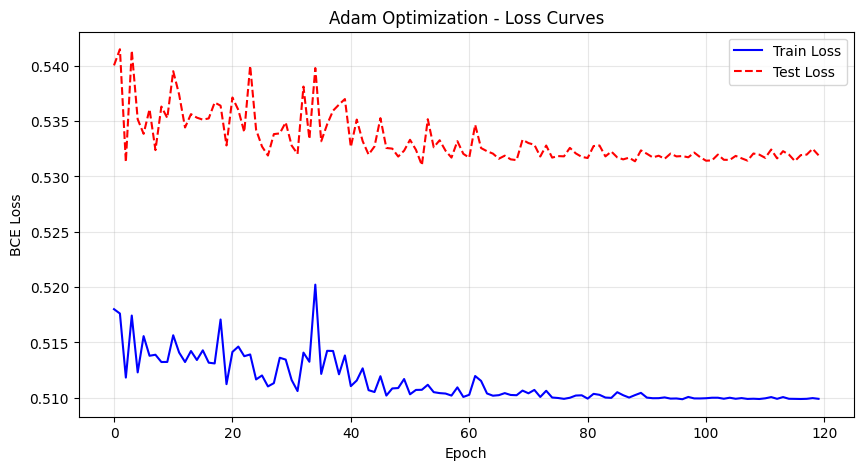

In [4]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# 1. توليد وتجهيز البيانات
X, y = make_classification(
    n_samples=4000, n_features=12, n_informative=8, n_redundant=2, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 2. الدوال المساعدة
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def bce_loss(y_true, y_prob):
    y_prob = np.clip(y_prob, 1e-12, 1.0 - 1e-12)
    return -np.mean(y_true * np.log(y_prob) + (1.0 - y_true) * np.log(1.0 - y_prob))

# 3. إعداد المعاملات الرياضية لمحسن Adam
rng = np.random.default_rng(42)
w = np.zeros(X_train.shape[1])
b = 0.0
m_w = np.zeros(X_train.shape[1])
m_b = 0.0
s_w = np.zeros(X_train.shape[1])
s_b = 0.0

initial_lr = 0.05
beta1 = 0.9
beta2 = 0.999
eps = 1e-8
batch_size = 64
epochs = 120
step = 0

train_losses = []
test_losses = []

# 4. حلقة التدريب المحسنة
t0 = time.perf_counter()
for epoch in range(epochs):
    idx = rng.permutation(len(y_train))
    # جدولة معدل التعلم (Cos-decay تقريبي أو اضمحلال تدريجي)
    lr = initial_lr * (0.98 ** epoch)

    for start in range(0, len(y_train), batch_size):
        step += 1
        batch = idx[start : start + batch_size]
        Xb, yb = X_train[batch], y_train[batch]

        err = sigmoid(Xb @ w + b) - yb
        dw = (Xb.T @ err) / len(yb)
        db = np.mean(err)

        # تحديث العزوم لـ Adam
        m_w = beta1 * m_w + (1.0 - beta1) * dw
        m_b = beta1 * m_b + (1.0 - beta1) * db
        s_w = beta2 * s_w + (1.0 - beta2) * (dw ** 2)
        s_b = beta2 * s_b + (1.0 - beta2) * (db ** 2)

        # تصحيح الانحياز
        m_w_hat = m_w / (1.0 - beta1 ** step)
        m_b_hat = m_b / (1.0 - beta1 ** step)
        s_w_hat = s_w / (1.0 - beta2 ** step)
        s_b_hat = s_b / (1.0 - beta2 ** step)

        # تحديث الأوزان والانحياز
        w -= lr * m_w_hat / (np.sqrt(s_w_hat) + eps)
        b -= lr * m_b_hat / (np.sqrt(s_b_hat) + eps)

    # تسجيل الخسائر لكل حقبة (Epoch)
    train_losses.append(bce_loss(y_train, sigmoid(X_train @ w + b)))
    test_losses.append(bce_loss(y_test, sigmoid(X_test @ w + b)))

train_time = time.perf_counter() - t0

# 5. التقييم النهائي
test_preds = (sigmoid(X_test @ w + b) >= 0.5).astype(int)
print(f"Train Time: {train_time:.4f}s | Final Train Loss: {train_losses[-1]:.4f} | Final Test Loss: {test_losses[-1]:.4f}")
print(f"Test Accuracy: {accuracy_score(y_test, test_preds):.4f} | Test F1: {f1_score(y_test, test_preds):.4f}")

# 6. رسم بياني للخسائر
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(test_losses, label='Test Loss', color='red', linestyle='--')
plt.title("Adam Optimization - Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()